# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_:
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael J.
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

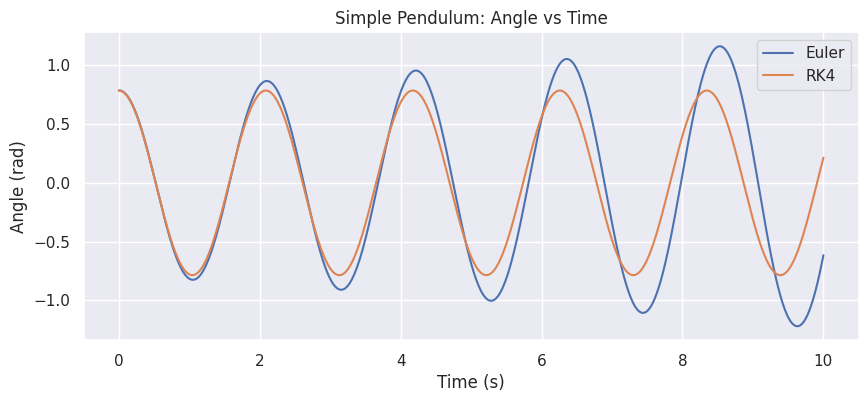

In [2]:
# practice mode

# The two general solvers from Section 3, brought up here so the notebook runs
# top to bottom. Both step a whole state VECTOR, so the same two functions handle
# the pendulum, the 3-variable Lorenz system and every oscillator below.

def eulergen(f, a, b, n, yinit):
    """Forward Euler for y' = f(t, y). One slope per step, global error O(h)."""
    h = (b - a) / (n - 1)
    ts = a + np.arange(n) * h
    ys = np.empty((n, len(yinit)))
    ys[0] = yinit
    for j in range(n - 1):
        ys[j + 1] = ys[j] + h * f(ts[j], ys[j])
    return ts, ys


def rk4gen(f, a, b, n, yinit):
    """4th-order Runge-Kutta for y' = f(t, y). Four slopes, global error O(h^4)."""
    h = (b - a) / (n - 1)
    ts = a + np.arange(n) * h
    ys = np.empty((n, len(yinit)))
    ys[0] = yinit
    for j in range(n - 1):
        t, y = ts[j], ys[j]
        k0 = f(t,         y)                  # slope at the start
        k1 = f(t + h / 2, y + h / 2 * k0)     # midpoint, stepped there with k0
        k2 = f(t + h / 2, y + h / 2 * k1)     # midpoint again, using k1
        k3 = f(t + h,     y + h * k2)         # slope at the end
        ys[j + 1] = y + h / 6 * (k0 + 2 * k1 + 2 * k2 + k3)
    return ts, ys


# global constants
g = 9.81
l = 1.0

def pendulum_ode(t, R):
    # R is a vector containing the two variables theta, omega
    theta, omega = R
    f0 = omega
    f1 = -(g / l) * np.sin(theta)
    return np.array([f0, f1])


# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n
a, b, n = 0.0, 10.0, 1000

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = np.array([np.pi / 4, 0.0])   # theta0, omega0

t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

In [3]:
def lorenz(t, state, sigma, rho, beta):
  x, y, z = state
  dxdt = sigma * (y - x)
  dydt = x * (rho - z) - y
  dzdt = x * y - beta * z
  return np.array([dxdt, dydt, dzdt])

In [4]:
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0

initial_state = np.array([0.0, 1.0, 0.0])  # x(0)=0, y(0)=1, z(0)=0
t_start, t_end = 0.0, 50.0
num_steps = 25000  # Step size dt = 0.002

In [5]:
# rk4gen from Section 3 builds its own time grid and takes n points, not n steps
t, states = rk4gen(lambda t, R: lorenz(t, R, sigma, rho, beta),
                   t_start, t_end, num_steps + 1, initial_state)
dt = t[1] - t[0]

x = states[:, 0]
y = states[:, 1]
z = states[:, 2]

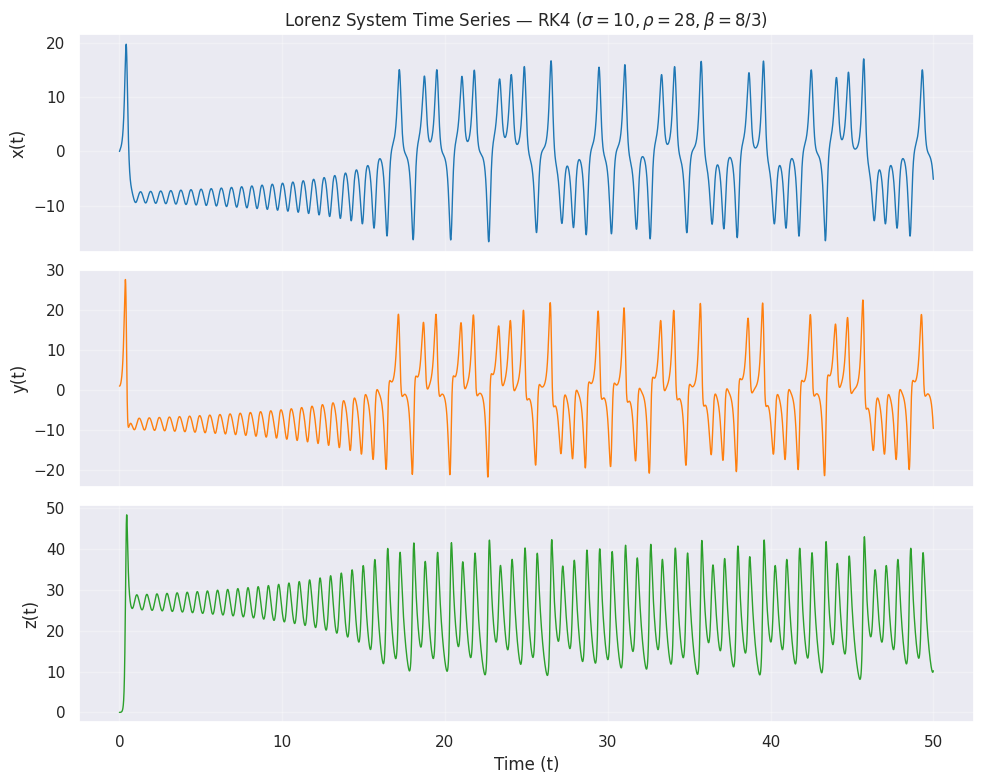

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(t, x, color="tab:blue", linewidth=1)
axes[0].set_ylabel("x(t)")
axes[0].set_title(
    r"Lorenz System Time Series — RK4 ($\sigma=10, \rho=28, \beta=8/3$)"
)
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, y, color="tab:orange", linewidth=1)
axes[1].set_ylabel("y(t)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(t, z, color="tab:green", linewidth=1)
axes[2].set_ylabel("z(t)")
axes[2].set_xlabel("Time (t)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

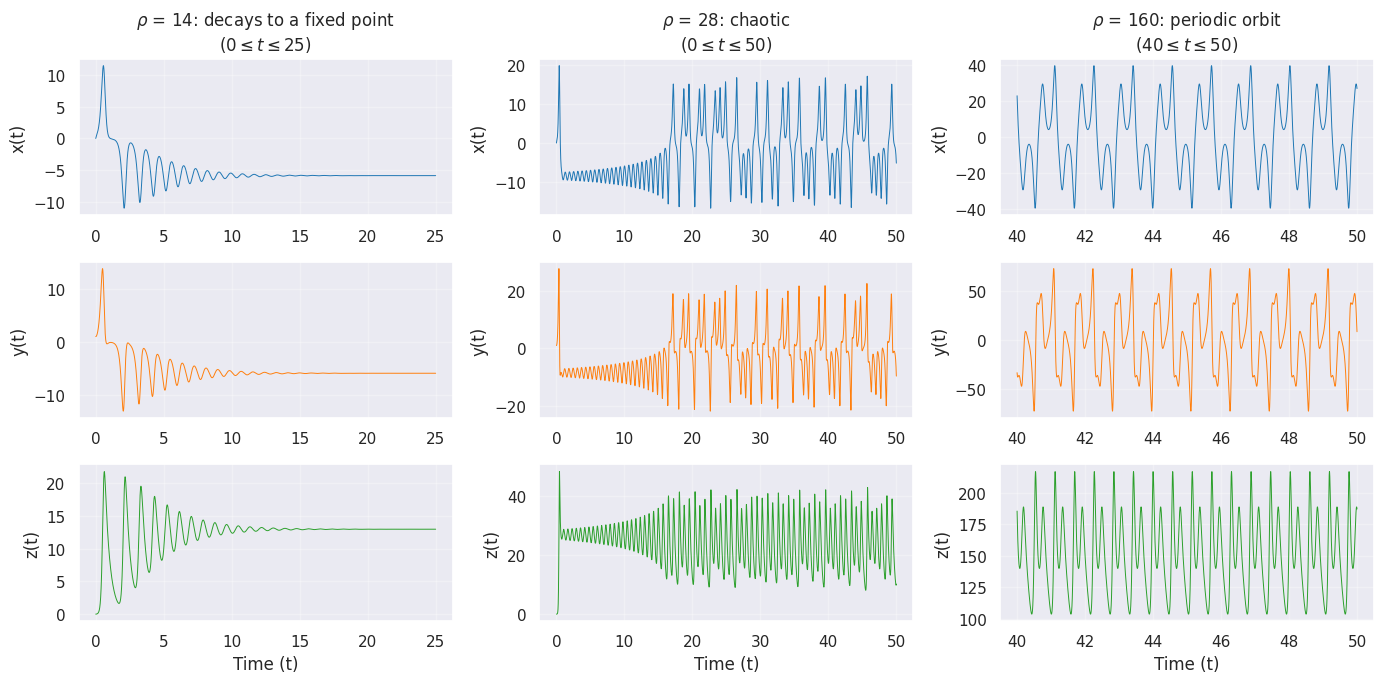

In [7]:
# Same equations at three values of rho. The fixed points lose stability at
# rho_H = sigma*(sigma + beta + 3)/(sigma - beta - 1) = 24.74.
rho_list = [14.0, 28.0, 160.0]
labels = ["decays to a fixed point", "chaotic", "periodic orbit"]
windows = [(0.0, 25.0), (0.0, 50.0), (40.0, 50.0)]

fig, axes = plt.subplots(3, 3, figsize=(14, 7))

for col, (r, lab, (w0, w1)) in enumerate(zip(rho_list, labels, windows)):
    tr, sr = rk4gen(lambda t, R: lorenz(t, R, sigma, r, beta),
                    t_start, t_end, num_steps + 1, initial_state)
    m = (tr >= w0) & (tr <= w1)
    for row, (name, color) in enumerate(zip("xyz", ["tab:blue", "tab:orange", "tab:green"])):
        axes[row, col].plot(tr[m], sr[m, row], color=color, linewidth=0.7)
        axes[row, col].set_ylabel(f"{name}(t)")
        axes[row, col].grid(True, alpha=0.3)
    axes[0, col].set_title(rf"$\rho$ = {r:g}: {lab}" + f"\n($ {w0:g} \\leq t \\leq {w1:g}$)")
    axes[2, col].set_xlabel("Time (t)")

plt.tight_layout()
plt.show()

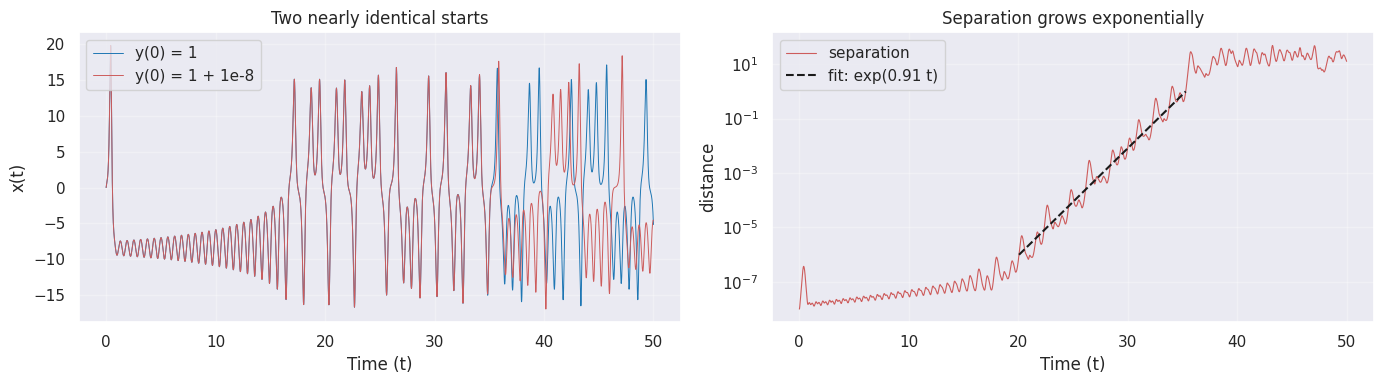

growth rate lambda = 0.907 (published Lyapunov exponent 0.906)


In [8]:
# Sensitivity to initial conditions: same equations, y(0) nudged by 1e-8
f28 = lambda t, R: lorenz(t, R, sigma, rho, beta)
tA, A = rk4gen(f28, t_start, t_end, num_steps + 1, np.array([0.0, 1.0, 0.0]))
tB, B = rk4gen(f28, t_start, t_end, num_steps + 1, np.array([0.0, 1.0 + 1e-8, 0.0]))
sep = np.linalg.norm(A - B, axis=1)

band = (sep > 1e-6) & (sep < 1.0)
lam = np.polyfit(tA[band], np.log(sep[band]), 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(tA, A[:, 0], color="tab:blue", linewidth=0.7, label="y(0) = 1")
axes[0].plot(tB, B[:, 0], color="indianred", linewidth=0.7, label="y(0) = 1 + 1e-8")
axes[0].set_title("Two nearly identical starts")
axes[0].set_xlabel("Time (t)")
axes[0].set_ylabel("x(t)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].semilogy(tA, sep, color="indianred", linewidth=0.8, label="separation")
axes[1].semilogy(tA[band], np.exp(np.polyval(np.polyfit(tA[band], np.log(sep[band]), 1), tA[band])),
                 "k--", linewidth=1.5, label=f"fit: exp({lam:.2f} t)")
axes[1].set_title("Separation grows exponentially")
axes[1].set_xlabel("Time (t)")
axes[1].set_ylabel("distance")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"growth rate lambda = {lam:.3f} (published Lyapunov exponent 0.906)")

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

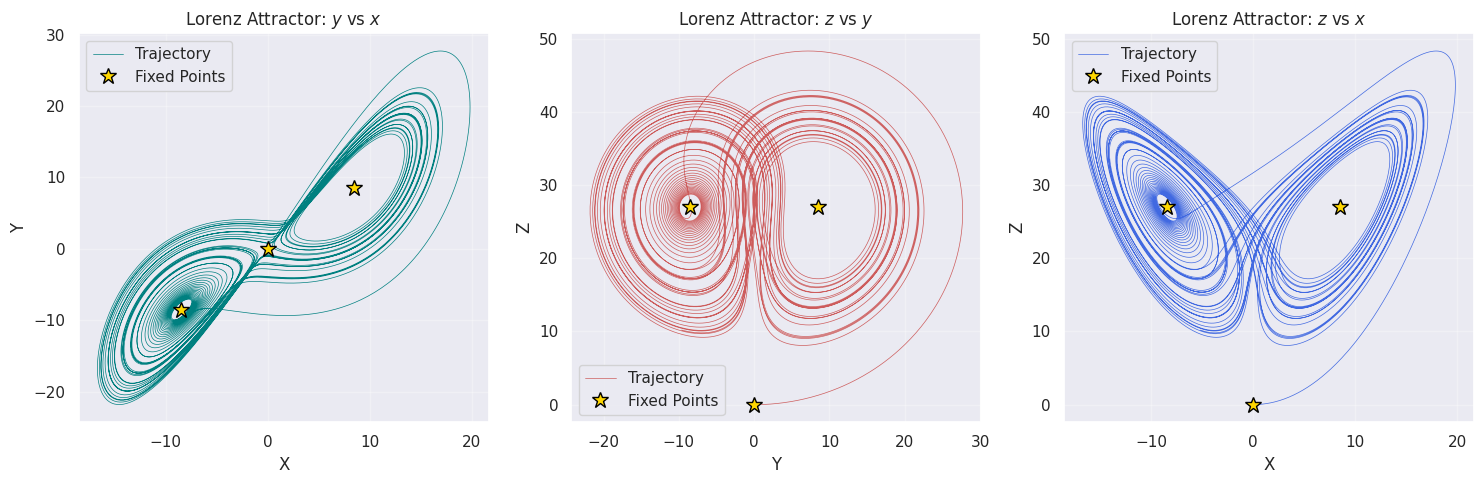

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Analytical fixed points of the Lorenz system (since rho > 1)
x_star = np.sqrt(beta * (rho - 1.0))
y_star = np.sqrt(beta * (rho - 1.0))
z_star = rho - 1.0

fixed_points = [
    (0.0, 0.0, 0.0),
    (x_star, y_star, z_star),
    (-x_star, -y_star, z_star)
]

#  Y vs X projection
axes[0].plot(x, y, color='teal', linewidth=0.5, label='Trajectory')
for idx, (fp_x, fp_y, fp_z) in enumerate(fixed_points):
    label = 'Fixed Points' if idx == 0 else ""
    axes[0].plot(fp_x, fp_y, '*', color='gold', markersize=12, markeredgecolor='black', label=label)
axes[0].set_title("Lorenz Attractor: $y$ vs $x$")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

#  Z vs Y projection
axes[1].plot(y, z, color='indianred', linewidth=0.5, label='Trajectory')
for idx, (fp_x, fp_y, fp_z) in enumerate(fixed_points):
    label = 'Fixed Points' if idx == 0 else ""
    axes[1].plot(fp_y, fp_z, '*', color='gold', markersize=12, markeredgecolor='black', label=label)
axes[1].set_title("Lorenz Attractor: $z$ vs $y$")
axes[1].set_xlabel("Y")
axes[1].set_ylabel("Z")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

#  Z vs X projection
axes[2].plot(x, z, color='royalblue', linewidth=0.5, label='Trajectory')
for idx, (fp_x, fp_y, fp_z) in enumerate(fixed_points):
    label = 'Fixed Points' if idx == 0 else ""
    axes[2].plot(fp_x, fp_z, '*', color='gold', markersize=12, markeredgecolor='black', label=label)
axes[2].set_title("Lorenz Attractor: $z$ vs $x$")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Z")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

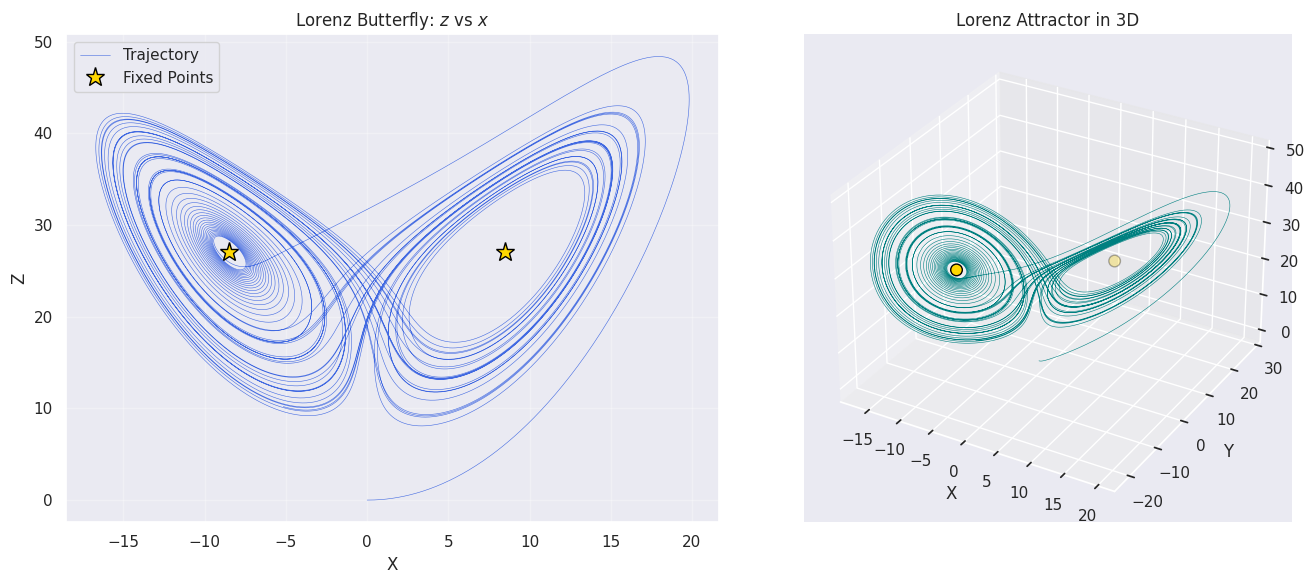

In [10]:
# The butterfly on its own, plus the same trajectory in 3D
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(x, z, color='royalblue', linewidth=0.4, label='Trajectory')
ax1.plot([x_star, -x_star], [z_star, z_star], '*', color='gold',
         markersize=14, markeredgecolor='black', linestyle='None', label='Fixed Points')
ax1.set_title("Lorenz Butterfly: $z$ vs $x$")
ax1.set_xlabel("X")
ax1.set_ylabel("Z")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot(x, y, z, color='teal', linewidth=0.4)
ax2.scatter([x_star, -x_star], [y_star, -y_star], [z_star, z_star],
            color='gold', edgecolor='black', s=70)
ax2.set_title("Lorenz Attractor in 3D")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")

plt.tight_layout()
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---


### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

In [11]:
def harmonic(t, R, omega):
  x, v = R
  return np.array([v, -omega**2 * x])


def period(t, x):
  # time between upward zero crossings, interpolated so dt does not limit it
  s = np.sign(x)
  i = np.nonzero((s[:-1] < 0) & (s[1:] >= 0))[0]
  tc = t[i] + (t[i+1] - t[i]) * (-x[i]) / (x[i+1] - x[i])
  return np.diff(tc).mean()

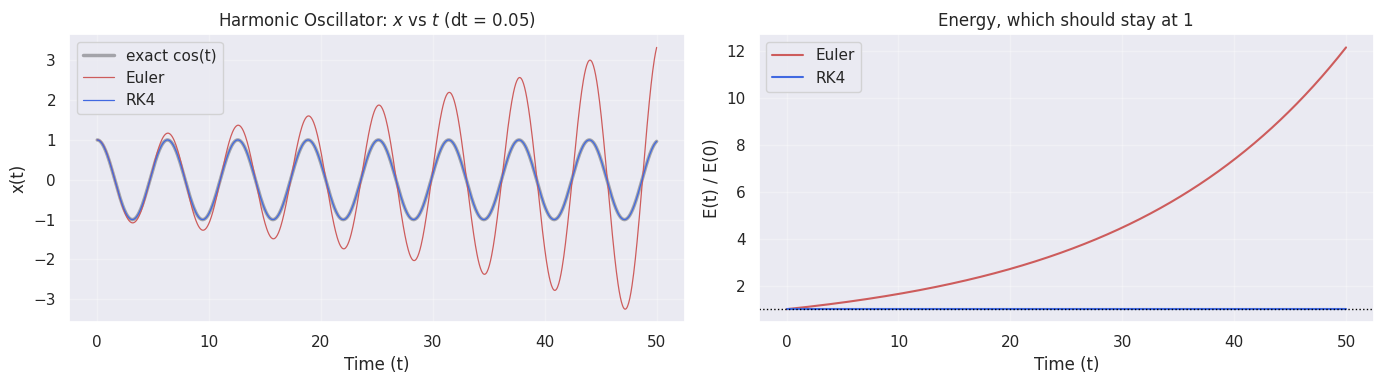

RK4   period = 6.283185   exact 2*pi = 6.283185
RK4   max|x| = 1.000000   energy x1.000000
Euler max|x| = 3.321873   energy x12.145


In [12]:
omega = 1.0
a, b, n = 0.0, 50.0, 1001  # dt = 0.05
yinit = np.array([1.0, 0.0])  # x(0)=1, dx/dt(0)=0

f_sho = lambda t, R: harmonic(t, R, omega)
t_e, Y_e = eulergen(f_sho, a, b, n, yinit)
t_r, Y_r = rk4gen(f_sho, a, b, n, yinit)
exact = np.cos(omega * t_r)

E_e = 0.5 * (Y_e[:, 1]**2 + omega**2 * Y_e[:, 0]**2)
E_r = 0.5 * (Y_r[:, 1]**2 + omega**2 * Y_r[:, 0]**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(t_r, exact, color='black', linewidth=2.5, alpha=0.3, label='exact cos(t)')
axes[0].plot(t_e, Y_e[:, 0], color='indianred', linewidth=0.9, label='Euler')
axes[0].plot(t_r, Y_r[:, 0], color='royalblue', linewidth=0.9, label='RK4')
axes[0].set_title(f"Harmonic Oscillator: $x$ vs $t$ (dt = {(b-a)/(n-1):g})")
axes[0].set_xlabel("Time (t)")
axes[0].set_ylabel("x(t)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_e, E_e / E_e[0], color='indianred', label='Euler')
axes[1].plot(t_r, E_r / E_r[0], color='royalblue', label='RK4')
axes[1].axhline(1.0, color='black', linestyle=':', linewidth=1)
axes[1].set_title("Energy, which should stay at 1")
axes[1].set_xlabel("Time (t)")
axes[1].set_ylabel("E(t) / E(0)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"RK4   period = {period(t_r, Y_r[:, 0]):.6f}   exact 2*pi = {2*np.pi:.6f}")
print(f"RK4   max|x| = {np.abs(Y_r[:, 0]).max():.6f}   energy x{E_r[-1]/E_r[0]:.6f}")
print(f"Euler max|x| = {np.abs(Y_e[:, 0]).max():.6f}   energy x{E_e[-1]/E_e[0]:.3f}")

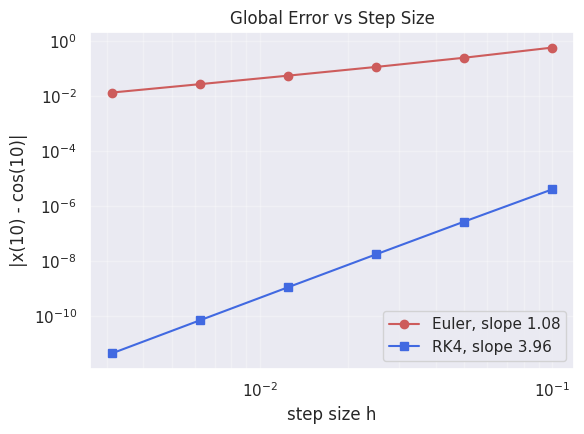

fitted order: Euler 1.08 (theory 1), RK4 3.96 (theory 4)


In [13]:
# Order of accuracy: global error at t = 10 against step size
steps = [101, 201, 401, 801, 1601, 3201]
hs, err_e, err_r = [], [], []

for npts in steps:
  hs.append(10.0 / (npts - 1))
  _, Ae = eulergen(f_sho, 0.0, 10.0, npts, yinit)
  _, Ar = rk4gen(f_sho, 0.0, 10.0, npts, yinit)
  err_e.append(abs(Ae[-1, 0] - np.cos(10.0)))
  err_r.append(abs(Ar[-1, 0] - np.cos(10.0)))

hs = np.array(hs)
p_e = np.polyfit(np.log(hs), np.log(err_e), 1)[0]
p_r = np.polyfit(np.log(hs), np.log(err_r), 1)[0]

plt.figure(figsize=(6, 4.5))
plt.loglog(hs, err_e, 'o-', color='indianred', label=f"Euler, slope {p_e:.2f}")
plt.loglog(hs, err_r, 's-', color='royalblue', label=f"RK4, slope {p_r:.2f}")
plt.title("Global Error vs Step Size")
plt.xlabel("step size h")
plt.ylabel("|x(10) - cos(10)|")
plt.grid(True, alpha=0.3, which='both')
plt.legend()
plt.tight_layout()
plt.show()

print(f"fitted order: Euler {p_e:.2f} (theory 1), RK4 {p_r:.2f} (theory 4)")

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

x(0) = 0.5   period = 6.283185
x(0) = 1.0   period = 6.283185
x(0) = 2.0   period = 6.283185


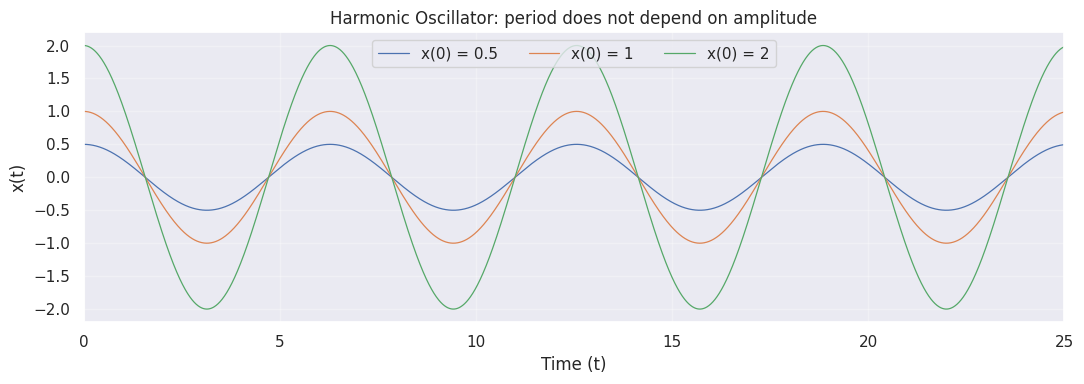

In [14]:
amplitudes = [0.5, 1.0, 2.0]

plt.figure(figsize=(11, 4))
for A in amplitudes:
  tA, YA = rk4gen(f_sho, 0.0, 50.0, 5001, np.array([A, 0.0]))
  plt.plot(tA, YA[:, 0], linewidth=0.9, label=f"x(0) = {A:g}")
  print(f"x(0) = {A:3.1f}   period = {period(tA, YA[:, 0]):.6f}")

plt.title("Harmonic Oscillator: period does not depend on amplitude")
plt.xlabel("Time (t)")
plt.ylabel("x(t)")
plt.xlim(0, 25)
plt.grid(True, alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

x(0) = 0.5   period = 14.83260   theory 14.83260
x(0) = 1.0   period =  7.41630   theory  7.41630
x(0) = 2.0   period =  3.70815   theory  3.70815


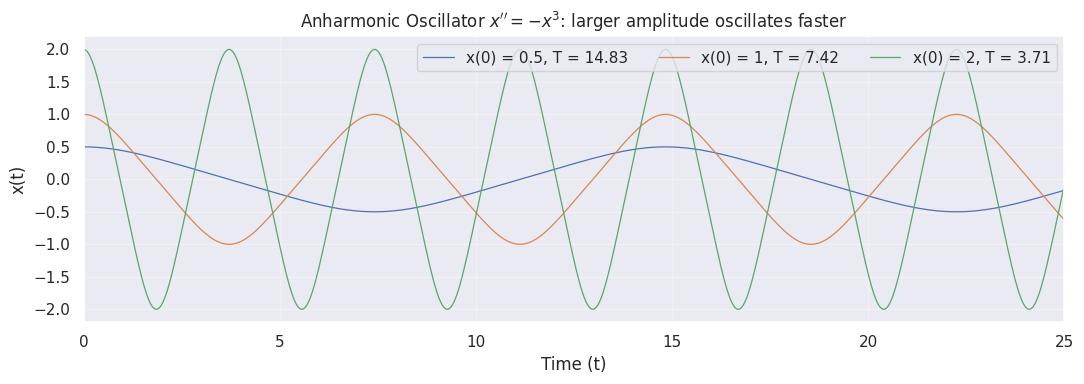

In [15]:
from scipy.special import gamma

def anharmonic(t, R, omega):
  x, v = R
  return np.array([v, -omega**2 * x**3])

# closed form: T = sqrt(2) * Gamma(1/4) * Gamma(1/2) / (omega * A * Gamma(3/4))
T_const = np.sqrt(2) * gamma(0.25) * gamma(0.5) / gamma(0.75)
f_anh = lambda t, R: anharmonic(t, R, omega)

plt.figure(figsize=(11, 4))
for A in amplitudes:
  tA, YA = rk4gen(f_anh, 0.0, 50.0, 100001, np.array([A, 0.0]))
  T = period(tA, YA[:, 0])
  plt.plot(tA, YA[:, 0], linewidth=0.9, label=f"x(0) = {A:g}, T = {T:.2f}")
  print(f"x(0) = {A:3.1f}   period = {T:8.5f}   theory {T_const/A:8.5f}")

plt.title("Anharmonic Oscillator $x'' = -x^3$: larger amplitude oscillates faster")
plt.xlabel("Time (t)")
plt.ylabel("x(t)")
plt.xlim(0, 25)
plt.grid(True, alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

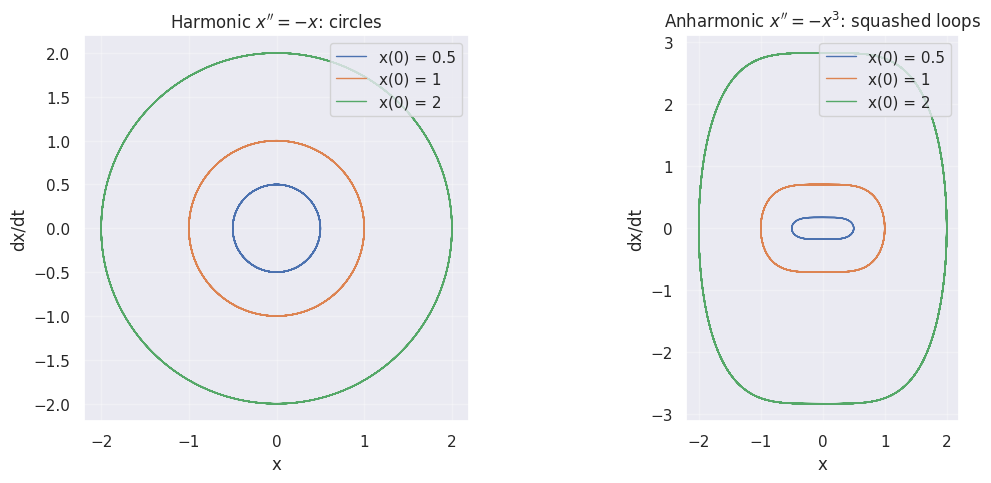

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for A in amplitudes:
  _, Yh = rk4gen(f_sho, 0.0, 50.0, 5001, np.array([A, 0.0]))
  _, Ya = rk4gen(f_anh, 0.0, 50.0, 100001, np.array([A, 0.0]))
  axes[0].plot(Yh[:, 0], Yh[:, 1], linewidth=1.0, label=f"x(0) = {A:g}")
  axes[1].plot(Ya[:, 0], Ya[:, 1], linewidth=1.0, label=f"x(0) = {A:g}")

axes[0].set_title("Harmonic $x'' = -x$: circles")
axes[1].set_title("Anharmonic $x'' = -x^3$: squashed loops")
for ax in axes:
  ax.set_xlabel("x")
  ax.set_ylabel("dx/dt")
  ax.set_aspect('equal')
  ax.grid(True, alpha=0.3)
  ax.legend()

plt.tight_layout()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

mu = 1   period =  6.6633   max|x| = 2.0086
mu = 2   period =  7.6299   max|x| = 2.0199
mu = 4   period = 10.2035   max|x| = 2.0230


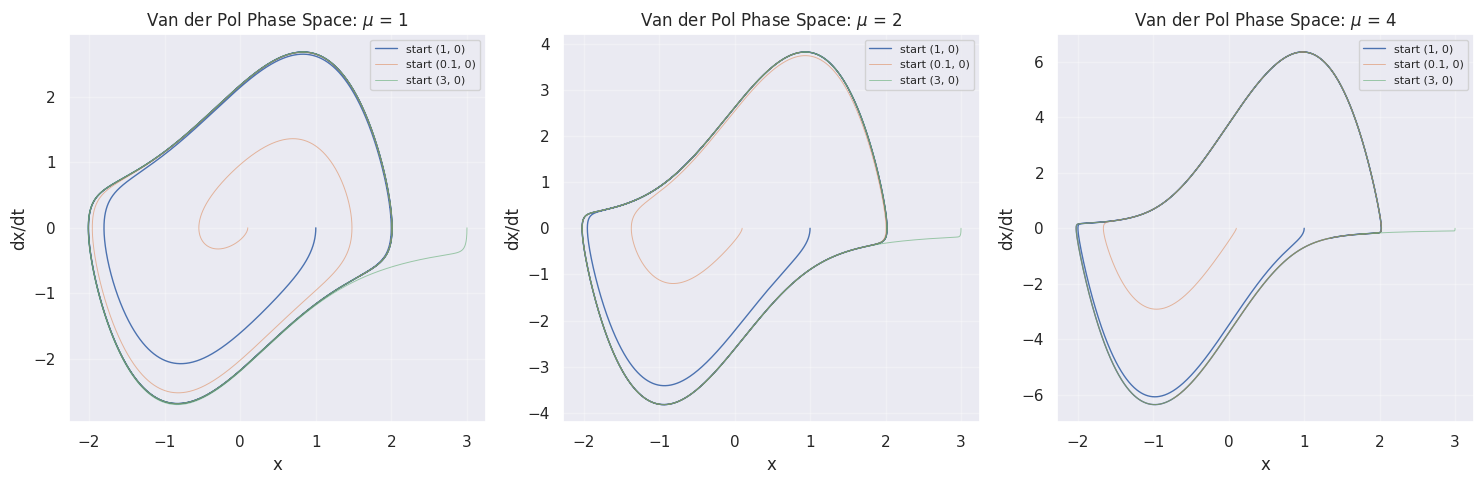

In [17]:
def vanderpol(t, R, mu, omega):
  x, v = R
  return np.array([v, mu * (1.0 - x**2) * v - omega**2 * x])


mu_list = [1.0, 2.0, 4.0]
starts = [np.array([1.0, 0.0]), np.array([0.1, 0.0]), np.array([3.0, 0.0])]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, mu in zip(axes, mu_list):
  f_vdp = lambda t, R: vanderpol(t, R, mu, omega)
  for k, y0 in enumerate(starts):
    _, Y = rk4gen(f_vdp, 0.0, 20.0, 20001, y0)
    ax.plot(Y[:, 0], Y[:, 1], linewidth=1.0 if k == 0 else 0.7,
            alpha=1.0 if k == 0 else 0.55, label=f"start ({y0[0]:g}, 0)")
  tl, Yl = rk4gen(f_vdp, 0.0, 60.0, 60001, starts[0])
  late = tl > 30
  print(f"mu = {mu:g}   period = {period(tl[late], Yl[late, 0]):7.4f}   "
        f"max|x| = {np.abs(Yl[late, 0]).max():.4f}")
  ax.set_title(rf"Van der Pol Phase Space: $\mu$ = {mu:g}")
  ax.set_xlabel("x")
  ax.set_ylabel("dx/dt")
  ax.grid(True, alpha=0.3)
  ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [18]:
# dt check for the sharpest case, mu = 4
f_vdp4 = lambda t, R: vanderpol(t, R, 4.0, omega)
for npts in [2001, 20001, 200001]:
  _, Y = rk4gen(f_vdp4, 0.0, 20.0, npts, starts[0])
  print(f"dt = {20.0/(npts-1):.4f}   (x, v) at t = 20 = ({Y[-1, 0]:+.6f}, {Y[-1, 1]:+.6f})")

dt = 0.0100   (x, v) at t = 20 = (+1.352053, -0.348181)
dt = 0.0010   (x, v) at t = 20 = (+1.352052, -0.348181)
dt = 0.0001   (x, v) at t = 20 = (+1.352052, -0.348181)


#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---


---
## Section 3: Notes

In [19]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [20]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [21]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

[19.53       17.3817     15.469713   13.76804457 12.25355967]
[19.53       17.4998565  15.68074642 14.05073283 12.59015915]
[19.53       17.49564324 15.67319674 14.04058671 12.57803871]


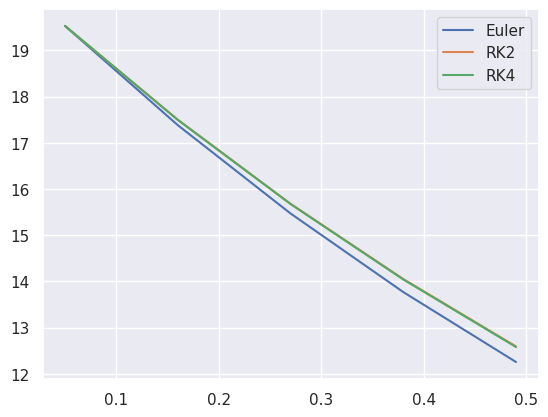

In [22]:
# execution
a, b, n, yinit = 0.05, 0.49, 5, 19.53

def f(x, y):
    # Returning a standard first-order ODE dy/dx = -y
    return -y

xs, ys = euler(f, a, b, n, yinit); print(ys)
plt.plot(xs, ys, label='Euler')
xs, ys = rk2(f, a, b, n, yinit); print(ys)
plt.plot(xs, ys, label='RK2')
xs, ys = rk4(f, a, b, n, yinit); print(ys)
plt.plot(xs, ys, label='RK4')
plt.legend()
plt.show()

#### Solving IVP problem of 2 simultaneous ODEs

In [23]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])

def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [24]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

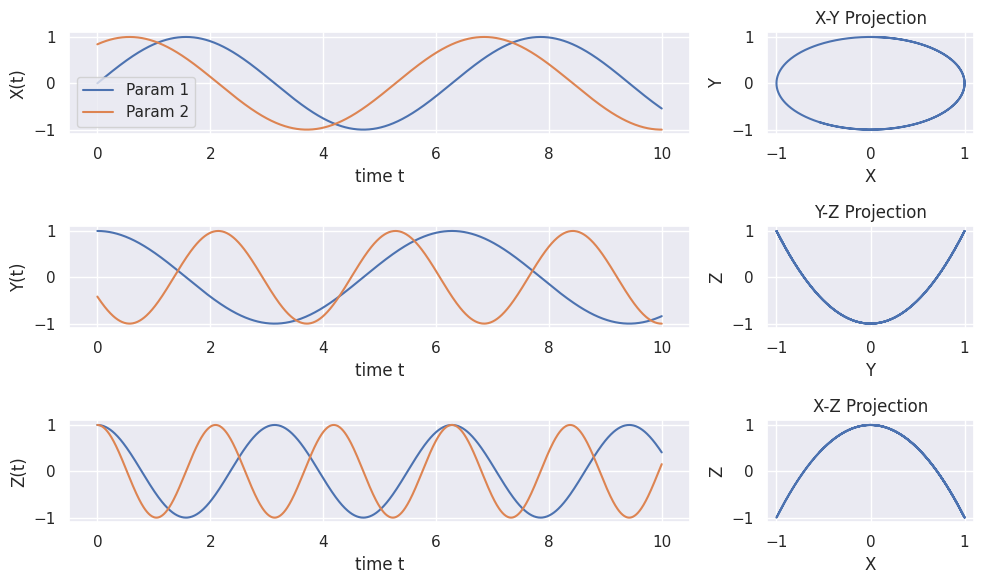

In [25]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()